In [1]:
!pip install -q pystac-client planetary-computer odc-stac rioxarray rasterio geopandas shapely segmentation-models-pytorch
!apt-get install -y -q gdal-bin 
!pip install -q mlflow optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.6/159.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.7/58.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.3 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 5.0 MB/s eta 0:00:00
Reading package lists...
Building dependency tree...
Reading state information...
gdal-bin is already the newest version (3.8.4+dfsg-3ubuntu3).
0 upgraded, 0 newly installed, 0 to remove and 125 not upgraded.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.2 MB/s eta 0:00:

In [2]:
import planetary_computer as pc, pystac_client, odc.stac, numpy as np
import rioxarray, matplotlib.pyplot as plt

BBOX = [48.55, 38.60, 48.80, 38.80]
CRS = "EPSG:32639"

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace)

# Sentinel-2 image
s2_items = catalog.search(
    collections=["sentinel-2-l2a"], bbox=BBOX,
    datetime="2021-06-01/2021-08-31",
    query={"eo:cloud_cover": {"lt": 20}}).item_collection()
print(len(s2_items), "scenes")

ds = odc.stac.load(s2_items, bands=["B04", "B03", "B02", "B08"],
                   bbox=BBOX, crs=CRS, resolution=10, chunks={})
img = ds.median("time").compute()

# WorldCover labels, snapped to the same grid
wc_items = catalog.search(collections=["esa-worldcover"], bbox=BBOX,
                          datetime="2021-01-01/2021-12-31").item_collection()
wc = odc.stac.load(wc_items, bands=["map"], like=ds, resampling="nearest").compute()
mask = (wc["map"].isel(time=0) == 10).astype("uint8")   # 10 = Tree cover

# Save as GeoTIFFs
arr = img[["B04", "B03", "B02", "B08"]].to_array("band").fillna(0).astype("uint16")
arr.rio.write_crs(CRS).rio.to_raster("s2.tif")
mask.rio.write_crs(CRS).rio.to_raster("mask.tif")

# Quick visual check
rgb = np.clip(arr.sel(band=["B04", "B03", "B02"]).values / 3000, 0, 1).transpose(1, 2, 0)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(rgb); ax[0].set_title("Sentinel-2 RGB")
ax[1].imshow(mask, cmap="Greens"); ax[1].set_title("WorldCover tree cover")
plt.show()
print("forest fraction:", float(mask.mean()))

APIError: You have exceeded a rate limit. Contact planetarycomputer@microsoft.com

In [8]:
!cp /kaggle/input/datasets/ruslanhasanov/lankaran-s2/s2.tif .
!cp /kaggle/input/datasets/ruslanhasanov/lankaran-s2/mask.tif .
!ls -lh s2.tif mask.tif

-rw-r--r-- 1 root root 4.9M Oct 18 09:06 mask.tif
-rw-r--r-- 1 root root  39M Oct 18 09:06 s2.tif


In [9]:
!pip install -q segmentation-models-pytorch rasterio geopandas shapely mlflow optuna
import torch
print("torch:", torch.__version__, "| CUDA:", torch.version.cuda, "| available:", torch.cuda.is_available())
!nvidia-smi -L

torch: 2.11.0+cu128 | CUDA: 12.8 | available: True
GPU 0: Tesla T4 (UUID: GPU-0a84f6e1-2640-9ccd-36f2-8ca0ddd4b6a3)
GPU 1: Tesla T4 (UUID: GPU-e4318382-c17f-61d6-5ebc-12418044fd27)


In [10]:
!gdalinfo s2.tif | head -30
!gdalinfo mask.tif | grep -E "Size is|Pixel Size|Origin|EPSG"

Driver: GTiff/GeoTIFF
Files: s2.tif
Size is 2232, 2276
Coordinate System is:
PROJCRS["WGS 84 / UTM zone 39N",
    BASEGEOGCRS["WGS 84",
        DATUM["World Geodetic System 1984",
            ELLIPSOID["WGS 84",6378137,298.257223563,
                LENGTHUNIT["metre",1]]],
        PRIMEM["Greenwich",0,
            ANGLEUNIT["degree",0.0174532925199433]],
        ID["EPSG",4326]],
    CONVERSION["UTM zone 39N",
        METHOD["Transverse Mercator",
            ID["EPSG",9807]],
        PARAMETER["Latitude of natural origin",0,
            ANGLEUNIT["degree",0.0174532925199433],
            ID["EPSG",8801]],
        PARAMETER["Longitude of natural origin",51,
            ANGLEUNIT["degree",0.0174532925199433],
            ID["EPSG",8802]],
        PARAMETER["Scale factor at natural origin",0.9996,
            SCALEUNIT["unity",1],
            ID["EPSG",8805]],
        PARAMETER["False easting",500000,
            LENGTHUNIT["metre",1],
            ID["EPSG",8806]],
        PARAMETER["Fa

In [12]:
import rasterio
a, b = rasterio.open("s2.tif"), rasterio.open("mask.tif")
print(a.transform == b.transform, a.shape == b.shape, a.crs == b.crs)
print(a.count, a.dtypes[0], b.dtypes[0])

True True True
4 uint16 uint8


In [13]:
import rasterio, numpy as np

# Load the scene from disk (check the files exist first)
!ls -lh s2.tif mask.tif

with rasterio.open("s2.tif") as f: X = f.read().astype("float32") / 10000   # (4, H, W)
with rasterio.open("mask.tif") as f: Y = f.read(1)                           # (H, W)
C, H, W = X.shape
print("scene size:", H, "x", W)

T = 256
TRAIN_X1 = 1100
EAST_X0 = TRAIN_X1 + 256            # 1356
VAL_Y1, TEST_Y0 = 1000, 1000 + 256  # val rows 0-1000, test rows 1256-end

def make_tiles(r0, r1, c0, c1, stride):
    xs, ys = [], []
    for r in range(r0, r1 - T + 1, stride):
        for c in range(c0, c1 - T + 1, stride):
            x, y = X[:, r:r+T, c:c+T], Y[r:r+T, c:c+T]
            if (x.sum(0) == 0).mean() > 0.05: continue
            xs.append(x); ys.append(y)
    return np.stack(xs), np.stack(ys)

Xtr, Ytr = make_tiles(0, H, 0, TRAIN_X1, 128)
Xva, Yva = make_tiles(0, VAL_Y1, EAST_X0, W, 128)
# No test tiles are built: the test block is only touched once, at the very end.

mean = Xtr.mean(axis=(0, 2, 3), keepdims=True)
std = Xtr.std(axis=(0, 2, 3), keepdims=True)
Xtr, Xva = (Xtr - mean) / std, (Xva - mean) / std
Xn = ((X - mean[0]) / std[0]).astype("float32")      # full normalized scene, for test inference

print("train:", Xtr.shape, "forest frac:", round(float(Ytr.mean()), 3))
print("val:  ", Xva.shape, "forest frac:", round(float(Yva.mean()), 3))
print("test block label forest frac:", round(float(Y[TEST_Y0:, EAST_X0:].mean()), 3))

-rw-r--r-- 1 root root 4.9M Oct 18 09:06 mask.tif
-rw-r--r-- 1 root root  39M Oct 18 09:06 s2.tif
scene size: 2276 x 2232
train: (112, 4, 256, 256) forest frac: 0.775
val:   (30, 4, 256, 256) forest frac: 0.7
test block label forest frac: 0.892


In [14]:
import torch, torch.nn as nn, numpy as np
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader
import mlflow

device = "cuda"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("forest-segmentation")

class Tiles(Dataset):
    def __init__(self, X, Y, aug=False): self.X, self.Y, self.aug = X, Y, aug
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x, y = torch.from_numpy(self.X[i]), torch.from_numpy(self.Y[i]).float()[None]
        if self.aug:
            k = np.random.randint(4)
            x, y = torch.rot90(x, k, (1, 2)), torch.rot90(y, k, (1, 2))
            if np.random.rand() < 0.5: x, y = x.flip(2), y.flip(2)
        return x, y

def evaluate(model, loader):
    model.eval(); tp = fp = fn = tn = 0
    with torch.no_grad():
        for x, y in loader:
            p = (model(x.to(device)).sigmoid() > 0.5).cpu(); y = y.bool()
            tp += (p & y).sum().item(); fp += (p & ~y).sum().item()
            fn += (~p & y).sum().item(); tn += (~p & ~y).sum().item()
    iou_f, iou_n = tp / (tp + fp + fn), tn / (tn + fn + fp)
    return dict(iou_forest=iou_f, iou_nonforest=iou_n, miou=(iou_f + iou_n) / 2,
                dice_forest=2 * tp / (2 * tp + fp + fn), acc=(tp + tn) / (tp + tn + fp + fn))

def train_model(cfg, epochs, seed=0, save_path=None, log_epochs=True):
    torch.manual_seed(seed); np.random.seed(seed)
    chs = cfg.get("chs", [0, 1, 2, 3])
    tr_ = DataLoader(Tiles(Xtr[:, chs], Ytr, aug=True), batch_size=cfg["batch_size"], shuffle=True)
    va_ = DataLoader(Tiles(Xva[:, chs], Yva), batch_size=16)
    m = smp.Unet(cfg["encoder"], encoder_weights="imagenet", in_channels=len(chs), classes=1).to(device)
    dice_l, bce_l = smp.losses.DiceLoss("binary"), nn.BCEWithLogitsLoss()
    opt = torch.optim.AdamW(m.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    best = dict(miou=-1)
    for ep in range(epochs):
        m.train()
        for x, y in tr_:
            x, y = x.to(device), y.to(device); out = m(x)
            loss = dice_l(out, y) + cfg["bce_w"] * bce_l(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
        s = evaluate(m, va_)
        if log_epochs: mlflow.log_metrics({f"val_{k}": v for k, v in s.items()}, step=ep)
        if s["miou"] > best["miou"]:
            best = dict(s, epoch=ep)
            if save_path: torch.save(m.state_dict(), save_path)
    return best

# --- sanity checks (the first three lines of output) ---
f = Yva.mean(); print(f"all-forest baseline on val: acc={f:.3f}, forest IoU={f:.3f}, non-forest IoU=0")
print("GPU available:", torch.cuda.is_available())

# --- smoke test: 1 epoch with your original settings ---
import time; t0 = time.time()
DEFAULT_CFG = dict(encoder="resnet34", lr=3e-4, wd=1e-2, bce_w=1.0, batch_size=16)
with mlflow.start_run(run_name="smoke-test"):
    mlflow.log_params(DEFAULT_CFG)
    r = train_model(DEFAULT_CFG, epochs=1)
print({k: round(v, 3) for k, v in r.items()})
print(f"1 epoch took {time.time() - t0:.0f} s")

2026/10/18 09:07:52 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 09:07:52 INFO mlflow.store.db.utils: Updating database tables
2026/10/18 09:07:54 INFO mlflow.tracking.fluent: Experiment with name 'forest-segmentation' does not exist. Creating a new experiment.


all-forest baseline on val: acc=0.700, forest IoU=0.700, non-forest IoU=0
GPU available: True


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

{'iou_forest': 0.691, 'iou_nonforest': 0.257, 'miou': 0.474, 'dice_forest': 0.817, 'acc': 0.721, 'epoch': 0}
1 epoch took 6 s


In [15]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)   # keep the output short
import mlflow

def objective(trial):
    cfg = dict(encoder=trial.suggest_categorical("encoder", ["resnet18", "resnet34"]),
               lr=trial.suggest_float("lr", 1e-4, 1e-3, log=True),
               wd=trial.suggest_float("wd", 1e-5, 1e-2, log=True),
               bce_w=trial.suggest_float("bce_w", 0.25, 2.0),
               batch_size=trial.suggest_categorical("batch_size", [8, 16]))
    with mlflow.start_run(run_name=f"trial-{trial.number}", nested=True):
        mlflow.log_params(cfg)
        best = train_model(cfg, epochs=8)
        mlflow.log_metric("best_val_miou", best["miou"])
    print(f"trial {trial.number:2d}  val mIoU={best['miou']:.3f}  {cfg}")
    return best["miou"]

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
# Trial 0 = your original settings, so you get a built-in "before tuning" reference
study.enqueue_trial(dict(encoder="resnet34", lr=3e-4, wd=1e-2, bce_w=1.0, batch_size=16))

with mlflow.start_run(run_name="optuna-search"):
    study.optimize(objective, n_trials=20)
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_val_miou", study.best_value)

print("\n=== SUMMARY ===")
print("default (trial 0):", round(study.trials[0].value, 3))
print("best:             ", round(study.best_value, 3), study.best_params)
vals = sorted(t.value for t in study.trials)
print("spread across trials: min", round(vals[0], 3), "median", round(vals[len(vals)//2], 3), "max", round(vals[-1], 3))

trial  0  val mIoU=0.798  {'encoder': 'resnet34', 'lr': 0.0003, 'wd': 0.01, 'bce_w': 1.0, 'batch_size': 16}
trial  1  val mIoU=0.798  {'encoder': 'resnet34', 'lr': 0.00040064836619643974, 'wd': 0.0004311710058685488, 'bce_w': 0.9913958988430832, 'batch_size': 8}
trial  2  val mIoU=0.791  {'encoder': 'resnet34', 'lr': 0.0002417917724332947, 'wd': 0.0023723300729921923, 'bce_w': 1.175566109567583, 'batch_size': 16}
trial  3  val mIoU=0.761  {'encoder': 'resnet34', 'lr': 0.00010476552591086524, 'wd': 0.0031467304061660057, 'bce_w': 1.6117743141622383, 'batch_size': 16}


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

trial  4  val mIoU=0.801  {'encoder': 'resnet18', 'lr': 0.0006032942364042932, 'wd': 2.2637229697395473e-05, 'bce_w': 1.3698617873231667, 'batch_size': 16}
trial  5  val mIoU=0.793  {'encoder': 'resnet18', 'lr': 0.00018388894115254156, 'wd': 0.0021023308743480106, 'bce_w': 1.04826308137896, 'batch_size': 8}
trial  6  val mIoU=0.791  {'encoder': 'resnet18', 'lr': 0.00041393676083575454, 'wd': 0.006780227021579835, 'bce_w': 1.443185523431096, 'batch_size': 16}
trial  7  val mIoU=0.795  {'encoder': 'resnet18', 'lr': 0.0004642658243447121, 'wd': 0.0010278118224157004, 'bce_w': 0.6181694818792216, 'batch_size': 16}
trial  8  val mIoU=0.790  {'encoder': 'resnet34', 'lr': 0.000274537398149403, 'wd': 0.009228295957427444, 'bce_w': 0.4285784188090491, 'batch_size': 8}
trial  9  val mIoU=0.778  {'encoder': 'resnet18', 'lr': 0.0002926245594412446, 'wd': 5.410990556767878e-05, 'bce_w': 0.5281967713796595, 'batch_size': 16}
trial 10  val mIoU=0.796  {'encoder': 'resnet18', 'lr': 0.00057933816309437

In [16]:
best_cfg = study.best_params
res = {"default": [], "tuned": []}
with mlflow.start_run(run_name="seed-check"):
    for name, cfg in {"default": DEFAULT_CFG, "tuned": best_cfg}.items():
        for seed in (1, 2, 3):
            with mlflow.start_run(run_name=f"{name}-seed{seed}", nested=True):
                mlflow.log_params(cfg); mlflow.log_param("seed", seed)
                b = train_model(cfg, epochs=8, seed=seed, log_epochs=False)
                mlflow.log_metric("best_val_miou", b["miou"])
            res[name].append(b["miou"])
            print(name, "seed", seed, round(b["miou"], 3))

print("\n=== SEED CHECK ===")
for k, v in res.items():
    print(f"{k:8s} mean={np.mean(v):.3f}  std={np.std(v):.3f}")

default seed 1 0.803
default seed 2 0.748
default seed 3 0.794
tuned seed 1 0.781
tuned seed 2 0.772
tuned seed 3 0.788

=== SEED CHECK ===
default  mean=0.781  std=0.024
tuned    mean=0.780  std=0.007


In [17]:
best_cfg = study.best_params
print("training with:", best_cfg)

with mlflow.start_run(run_name="final-train") as run:
    final_run_id = run.info.run_id
    mlflow.log_params(best_cfg)
    final = train_model(best_cfg, epochs=15, seed=0, save_path="best.pt")
    mlflow.log_metrics({f"final_val_{k}": v for k, v in final.items() if k != "epoch"})
    mlflow.log_metric("final_best_epoch", final["epoch"])
    np.savez("norm.npz", mean=mean, std=std)
    mlflow.log_artifact("best.pt"); mlflow.log_artifact("norm.npz")

print({k: round(v, 3) for k, v in final.items()})
print("run id:", final_run_id)

# Rebuild `model` from the saved checkpoint (needed by the error analysis cell)
model = smp.Unet(best_cfg["encoder"], encoder_weights=None, in_channels=4, classes=1).to(device)
model.load_state_dict(torch.load("best.pt")); model.eval()
print("model reloaded from best.pt")

training with: {'encoder': 'resnet34', 'lr': 0.0007853826252105653, 'wd': 0.00013182267441633303, 'bce_w': 1.2551689690576497, 'batch_size': 8}
{'iou_forest': 0.851, 'iou_nonforest': 0.721, 'miou': 0.786, 'dice_forest': 0.92, 'acc': 0.893, 'epoch': 1}
run id: ae6a765078844e07b15c801a5d7afa2f
model reloaded from best.pt


false-positive px: 2.263%   false-negative px: 8.481%
non-forest recall: 0.925   non-forest precision: 0.766
tile error rates: {15: 0.001, 16: 0.004, 0: 0.273, 1: 0.266, 29: 0.236, 2: 0.211}


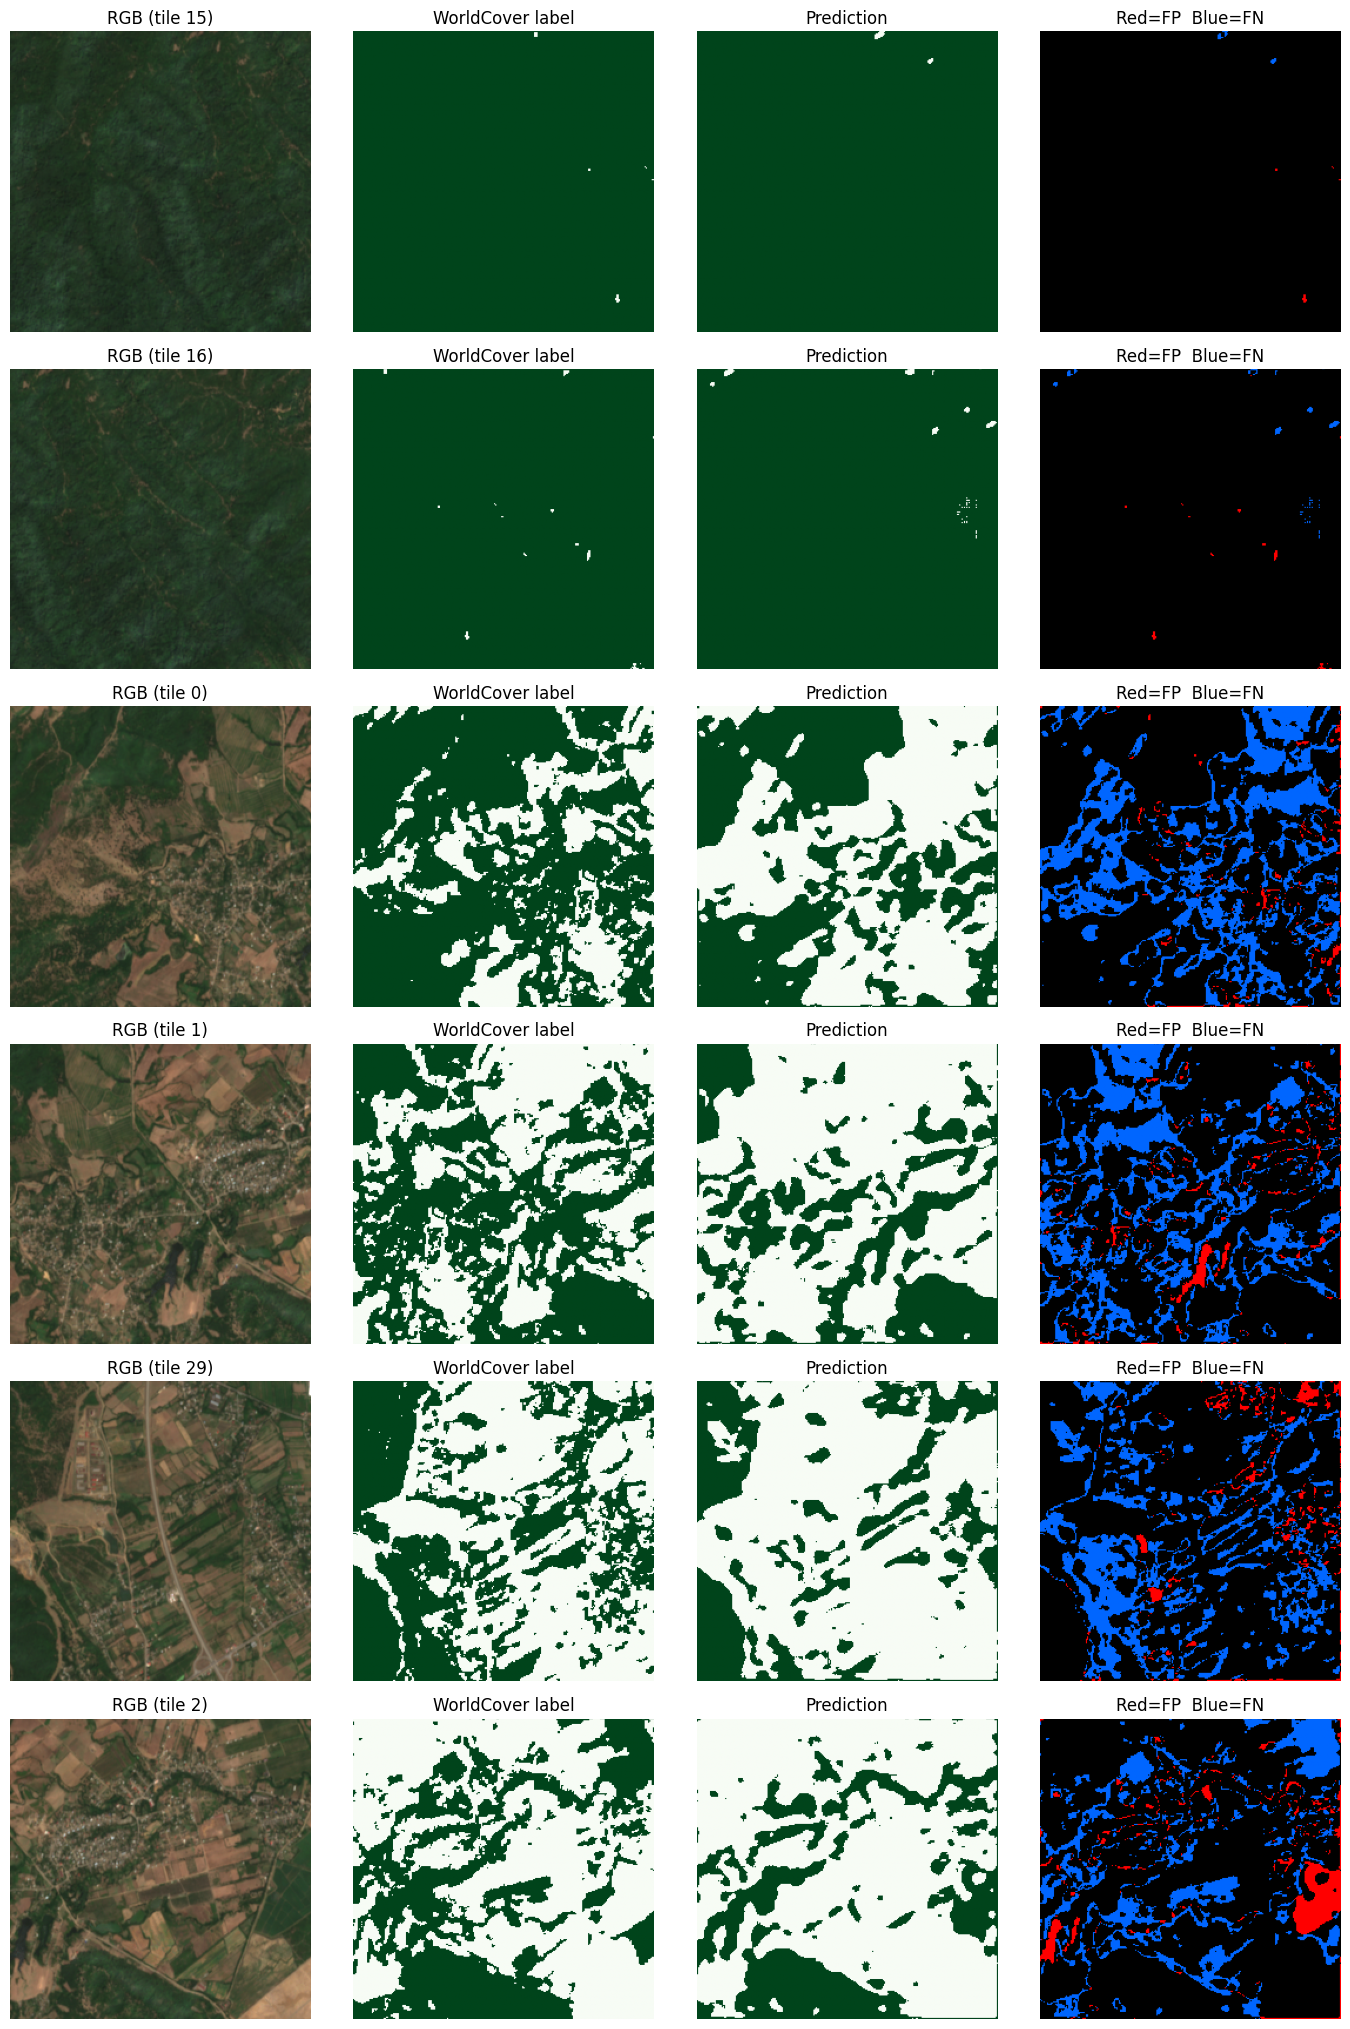

In [18]:
import matplotlib.pyplot as plt

model.load_state_dict(torch.load("best.pt")); model.eval()
with torch.no_grad():
    P = torch.cat([model(torch.from_numpy(Xva[i:i+16]).to(device)).sigmoid().cpu()
                   for i in range(0, len(Xva), 16)])[:, 0].numpy() > 0.5
Yb = Yva.astype(bool)
fp, fn = P & ~Yb, ~P & Yb          # fp = predicted forest, label says non-forest

print(f"false-positive px: {fp.mean():.3%}   false-negative px: {fn.mean():.3%}")
print(f"non-forest recall: {(~P & ~Yb).sum() / (~Yb).sum():.3f}   "
      f"non-forest precision: {(~P & ~Yb).sum() / (~P).sum():.3f}")

err = (fp | fn).mean(axis=(1, 2))   # per-tile error rate
worst = np.argsort(err)[::-1][:4]
best_t = np.argsort(err)[:2]
idx = list(best_t) + list(worst)
print("tile error rates:", {int(i): round(float(err[i]), 3) for i in idx})

fig, ax = plt.subplots(len(idx), 4, figsize=(14, 3.4 * len(idx)))
for r, i in enumerate(idx):
    rgb_t = np.clip((Xva[i] * std[0] + mean[0])[:3].transpose(1, 2, 0) / 0.3, 0, 1)
    e = np.zeros((*P[i].shape, 3)); e[fp[i]] = [1, 0, 0]; e[fn[i]] = [0, 0.4, 1]
    for a, im, t in zip(ax[r], [rgb_t, Yb[i], P[i], e],
                        [f"RGB (tile {i})", "WorldCover label", "Prediction", "Red=FP  Blue=FN"]):
        a.imshow(im, cmap="Greens" if im.ndim == 2 else None); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig("error_analysis.png", dpi=120); plt.show()

In [19]:
rows_i, cols_i = np.arange(len(err)) // 5, np.arange(len(err)) % 5
for r in range(6):
    m = rows_i == r
    print(f"tile-row {r} (scene rows {r*128}-{r*128+256}): error={err[m].mean():.3f}  "
          f"FP={fp[m].mean():.3f}  FN={fn[m].mean():.3f}  "
          f"label forest={Yb[m].mean():.2f}  pred forest={P[m].mean():.2f}")

tile-row 0 (scene rows 0-256): error=0.218  FP=0.043  FN=0.175  label forest=0.46  pred forest=0.33
tile-row 1 (scene rows 128-384): error=0.162  FP=0.037  FN=0.125  label forest=0.60  pred forest=0.51
tile-row 2 (scene rows 256-512): error=0.081  FP=0.019  FN=0.061  label forest=0.72  pred forest=0.68
tile-row 3 (scene rows 384-640): error=0.045  FP=0.013  FN=0.032  label forest=0.78  pred forest=0.76
tile-row 4 (scene rows 512-768): error=0.049  FP=0.010  FN=0.040  label forest=0.83  pred forest=0.79
tile-row 5 (scene rows 640-896): error=0.090  FP=0.015  FN=0.076  label forest=0.82  pred forest=0.76


In [20]:
def starts(n, T, s):
    r = list(range(0, n - T + 1, s))
    if r[-1] != n - T: r.append(n - T)
    return r

def predict_block(m, r0, r1, c0, c1, stride=128):
    h, w = r1 - r0, c1 - c0
    prob = np.zeros((h, w), "float32"); cnt = np.zeros((h, w), "float32")
    with torch.no_grad():
        for r in starts(h, T, stride):
            for c in starts(w, T, stride):
                x = torch.from_numpy(Xn[:, r0+r:r0+r+T, c0+c:c0+c+T])[None].to(device)
                prob[r:r+T, c:c+T] += m(x).sigmoid()[0, 0].cpu().numpy()
                cnt[r:r+T, c:c+T] += 1
    return (prob / cnt) > 0.5

model.eval()
pt = predict_block(model, TEST_Y0, H, EAST_X0, W)
yt = Y[TEST_Y0:, EAST_X0:].astype(bool)
valid = X[:, TEST_Y0:, EAST_X0:].sum(0) != 0          # exclude nodata pixels
p, y = pt[valid], yt[valid]
tp, fp_, fn_, tn = (p & y).sum(), (p & ~y).sum(), (~p & y).sum(), (~p & ~y).sum()
test = dict(iou_forest=tp/(tp+fp_+fn_), iou_nonforest=tn/(tn+fn_+fp_),
            baseline_forest_iou=y.mean(), nonforest_share=1 - y.mean())
test["miou"] = (test["iou_forest"] + test["iou_nonforest"]) / 2
print({k: round(float(v), 3) for k, v in test.items()})

with mlflow.start_run(run_id=final_run_id):
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in test.items()})
    mlflow.log_artifact("error_analysis.png")

{'iou_forest': 0.937, 'iou_nonforest': 0.594, 'baseline_forest_iou': 0.892, 'nonforest_share': 0.108, 'miou': 0.766}


predicted forest (raster):   39,513 ha
predicted forest (polygons): 39,381 ha  (146 polygons >= 1 ha)
WorldCover forest:           39,513 ha
train (in-sample)  forest IoU=0.905  non-forest IoU=0.692  pred=20,005 ha  label=19,274 ha
val (selection)    forest IoU=0.830  non-forest IoU=0.755  pred=5,040 ha  label=5,493 ha


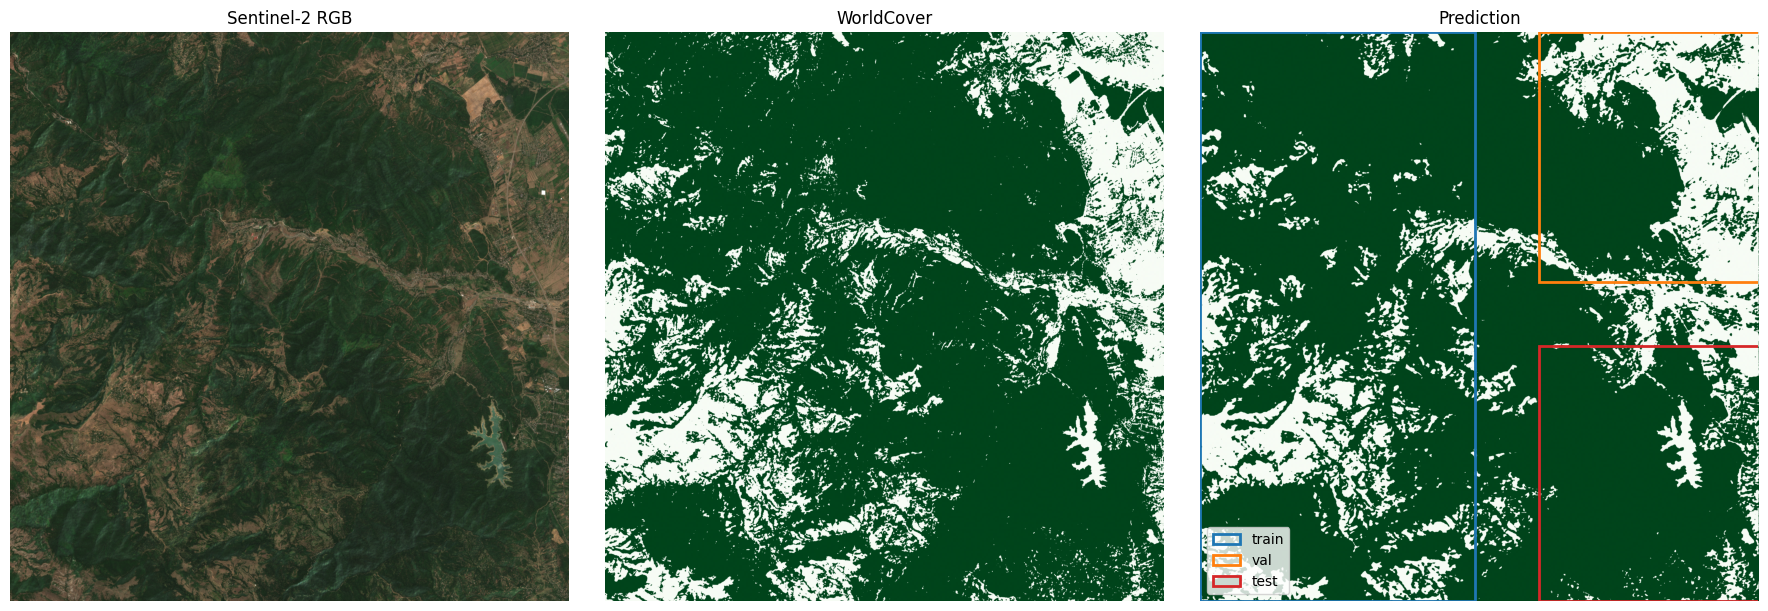

In [21]:
import rasterio, geopandas as gpd
from rasterio.features import shapes
from shapely.geometry import shape
import matplotlib.patches as mpatches

model.eval()
pred = predict_block(model, 0, H, 0, W).astype("uint8")   # defined in the test cell
pred[X.sum(0) == 0] = 0

with rasterio.open("s2.tif") as src: prof = src.profile
for k in ("blockxsize", "blockysize", "tiled"): prof.pop(k, None)
prof.update(count=1, dtype="uint8", nodata=None)
with rasterio.open("pred.tif", "w", **prof) as dst: dst.write(pred, 1)

with rasterio.open("pred.tif") as src:
    a, crs = src.read(1), src.crs
    geoms = [shape(g) for g, _ in shapes(a, mask=a == 1, transform=src.transform)]
gdf = gpd.GeoDataFrame(geometry=geoms, crs=crs)
gdf["ha"] = gdf.area / 1e4
gdf = gdf[gdf.ha >= 1].copy()
gdf.to_crs("EPSG:4326").to_file("forest.geojson", driver="GeoJSON")

print(f"predicted forest (raster):   {pred.sum() * 0.01:,.0f} ha")
print(f"predicted forest (polygons): {gdf.ha.sum():,.0f} ha  ({len(gdf)} polygons >= 1 ha)")
print(f"WorldCover forest:           {Y.sum() * 0.01:,.0f} ha")

def block_scores(r0, r1, c0, c1, name):
    p, y = pred[r0:r1, c0:c1].astype(bool), Y[r0:r1, c0:c1].astype(bool)
    ok = X[:, r0:r1, c0:c1].sum(0) != 0
    p, y = p[ok], y[ok]
    tp, fp_, fn_, tn = (p & y).sum(), (p & ~y).sum(), (~p & y).sum(), (~p & ~y).sum()
    print(f"{name:18s} forest IoU={tp/(tp+fp_+fn_):.3f}  non-forest IoU={tn/(tn+fn_+fp_):.3f}  "
          f"pred={p.sum()*0.01:,.0f} ha  label={y.sum()*0.01:,.0f} ha")
block_scores(0, H, 0, TRAIN_X1, "train (in-sample)")
block_scores(0, VAL_Y1, EAST_X0, W, "val (selection)")

rgb_full = np.clip(X[:3].transpose(1, 2, 0) / 0.3, 0, 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(rgb_full); ax[0].set_title("Sentinel-2 RGB")
ax[1].imshow(Y, cmap="Greens", vmin=0, vmax=1); ax[1].set_title("WorldCover")
ax[2].imshow(pred, cmap="Greens", vmin=0, vmax=1); ax[2].set_title("Prediction")
for (x0, y0, w_, h_), col, lab in [((0, 0, TRAIN_X1, H), "tab:blue", "train"),
                                   ((EAST_X0, 0, W - EAST_X0, VAL_Y1), "tab:orange", "val"),
                                   ((EAST_X0, TEST_Y0, W - EAST_X0, H - TEST_Y0), "tab:red", "test")]:
    ax[2].add_patch(mpatches.Rectangle((x0, y0), w_, h_, fill=False, ec=col, lw=2, label=lab))
ax[2].legend(loc="lower left")
for a_ in ax: a_.axis("off")
plt.tight_layout(); plt.savefig("forest_map.png", dpi=120); plt.show()

In [22]:
print("pred pixels:", int(pred.sum()), "| label pixels:", int(Y.sum()))
print("pixels where pred != label:", int((pred != Y).sum()))
print("same array object / identical?", pred is Y, bool((pred == Y).all()))
rest = np.ones((H, W), bool); rest[:, :TRAIN_X1] = False; rest[:VAL_Y1, EAST_X0:] = False
print("rest of scene (gaps + test): pred", int(pred[rest].sum()), "label", int(Y[rest].sum()))

pred pixels: 3951333 | label pixels: 3951300
pixels where pred != label: 413243
same array object / identical? False False
rest of scene (gaps + test): pred 1446879 label 1474540


In [23]:
!zip -qr results.zip best.pt norm.npz mlflow.db mlruns forest_map.png error_analysis.png forest.geojson pred.tif
!ls -lh results.zip

# Confirm what MLflow holds for the final run
from mlflow.tracking import MlflowClient
r = MlflowClient().get_run(final_run_id)
print({k: round(v, 3) for k, v in r.data.metrics.items() if k.startswith(("test_", "final_val_"))})
print(len(mlflow.search_runs(experiment_names=["forest-segmentation"])), "runs in MLflow")

-rw-r--r-- 1 root root 182M Oct 18 09:24 results.zip
{'final_val_iou_forest': 0.851, 'final_val_iou_nonforest': 0.721, 'final_val_miou': 0.786, 'final_val_dice_forest': 0.92, 'final_val_acc': 0.893, 'test_iou_forest': 0.937, 'test_iou_nonforest': 0.594, 'test_baseline_forest_iou': 0.892, 'test_nonforest_share': 0.108, 'test_miou': 0.766}
30 runs in MLflow


In [24]:
%%bash
pip install -q pytest
rm -rf forest-segmentation
mkdir -p forest-segmentation/forest_seg forest-segmentation/tests forest-segmentation/results forest-segmentation/notebooks
cd forest-segmentation

touch forest_seg/__init__.py

cat > forest_seg/tiling.py <<'EOF'
import numpy as np


def starts(n, tile, stride):
    """Window start offsets that always cover the far edge."""
    r = list(range(0, n - tile + 1, stride))
    if r[-1] != n - tile:
        r.append(n - tile)
    return r


def split_blocks(H, W, train_x1=1100, val_y1=1000, gap=256):
    """(r0, r1, c0, c1) per block.

    Train = west strip. The east strip is cut into val (top) and test (bottom).
    Every pair of blocks is separated by `gap` pixels to reduce spatial leakage.
    """
    east_x0 = train_x1 + gap
    return {
        "train": (0, H, 0, train_x1),
        "val": (0, val_y1, east_x0, W),
        "test": (val_y1 + gap, H, east_x0, W),
    }


def make_tiles(X, Y, block, tile=256, stride=128, max_nodata=0.05):
    """Cut tiles inside one block. X is (C,H,W), Y is (H,W). Skips tiles with nodata holes."""
    r0, r1, c0, c1 = block
    xs, ys = [], []
    for r in range(r0, r1 - tile + 1, stride):
        for c in range(c0, c1 - tile + 1, stride):
            x, y = X[:, r:r + tile, c:c + tile], Y[r:r + tile, c:c + tile]
            if (x.sum(0) == 0).mean() > max_nodata:
                continue
            xs.append(x)
            ys.append(y)
    if not xs:
        return np.empty((0, X.shape[0], tile, tile), X.dtype), np.empty((0, tile, tile), Y.dtype)
    return np.stack(xs), np.stack(ys)
EOF

cat > forest_seg/metrics.py <<'EOF'
import numpy as np


def confusion(pred, y):
    p, y = np.asarray(pred).astype(bool), np.asarray(y).astype(bool)
    return int((p & y).sum()), int((p & ~y).sum()), int((~p & y).sum()), int((~p & ~y).sum())


def scores(tp, fp, fn, tn):
    iou_f = tp / max(tp + fp + fn, 1)
    iou_n = tn / max(tn + fn + fp, 1)
    return dict(
        iou_forest=iou_f,
        iou_nonforest=iou_n,
        miou=(iou_f + iou_n) / 2,
        dice_forest=2 * tp / max(2 * tp + fp + fn, 1),
        acc=(tp + tn) / max(tp + fp + fn + tn, 1),
    )
EOF

cat > forest_seg/vectorize.py <<'EOF'
import geopandas as gpd
from rasterio.features import shapes
from shapely.geometry import shape


def mask_to_polygons(mask, transform, crs, min_ha=1.0):
    """Binary mask -> GeoDataFrame of forest polygons with area in hectares (crs must be metric)."""
    mask = mask.astype("uint8")
    geoms = [shape(g) for g, _ in shapes(mask, mask=mask == 1, transform=transform)]
    gdf = gpd.GeoDataFrame(geometry=geoms, crs=crs)
    gdf["ha"] = gdf.area / 1e4
    return gdf[gdf.ha >= min_ha].copy()
EOF

cat > tests/test_core.py <<'EOF'
import numpy as np
from rasterio.transform import from_origin

from forest_seg.metrics import scores
from forest_seg.tiling import make_tiles, split_blocks, starts
from forest_seg.vectorize import mask_to_polygons

H, W = 2276, 2232


def _gap(a, b):
    rows = max(a[0] - b[1], b[0] - a[1])
    cols = max(a[2] - b[3], b[2] - a[3])
    return max(rows, cols)


def test_starts_cover_far_edge():
    s = starts(600, 256, 128)
    assert s[0] == 0 and s[-1] == 600 - 256


def test_blocks_are_separated_by_buffer():
    b = split_blocks(H, W)
    for k1, k2 in [("train", "val"), ("train", "test"), ("val", "test")]:
        assert _gap(b[k1], b[k2]) >= 256, (k1, k2)


def test_blocks_stay_inside_scene():
    for r0, r1, c0, c1 in split_blocks(H, W).values():
        assert 0 <= r0 < r1 <= H and 0 <= c0 < c1 <= W


def test_tiles_stay_inside_their_block():
    X = np.ones((4, H, W), "float32")
    X[0] = np.arange(W)[None, :] + 1   # channel 0 encodes the column index
    X[1] = np.arange(H)[:, None] + 1   # channel 1 encodes the row index
    Y = np.zeros((H, W), "uint8")
    blocks = split_blocks(H, W)
    for name, (r0, r1, c0, c1) in blocks.items():
        Xt, Yt = make_tiles(X, Y, blocks[name])
        assert len(Xt) > 0 and Xt.shape[1:] == (4, 256, 256) and Yt.shape[1:] == (256, 256)
        assert Xt[:, 0].min() > c0 and Xt[:, 0].max() <= c1, name
        assert Xt[:, 1].min() > r0 and Xt[:, 1].max() <= r1, name


def test_nodata_tiles_are_skipped():
    X = np.ones((4, 256, 256), "float32")
    X[:, :100, :] = 0   # about 39% nodata
    Xt, _ = make_tiles(X, np.zeros((256, 256), "uint8"), (0, 256, 0, 256))
    assert len(Xt) == 0


def test_iou_values():
    s = scores(tp=50, fp=10, fn=10, tn=30)
    assert abs(s["iou_forest"] - 50 / 70) < 1e-9
    assert abs(s["iou_nonforest"] - 30 / 50) < 1e-9


def test_polygon_area_in_hectares():
    t = from_origin(0, 1000, 10, 10)             # 10 m pixels
    big = np.ones((100, 100), "uint8")           # 1 km x 1 km = 100 ha
    assert abs(mask_to_polygons(big, t, "EPSG:32639").ha.sum() - 100) < 1e-6
    speck = np.zeros((100, 100), "uint8")
    speck[:5, :5] = 1                            # 0.25 ha
    assert len(mask_to_polygons(speck, t, "EPSG:32639")) == 0
EOF

cat > requirements.txt <<'EOF'
numpy
torch
segmentation-models-pytorch
rasterio
geopandas
shapely
pystac-client
planetary-computer
odc-stac
rioxarray
mlflow
optuna
matplotlib
pytest
EOF

cat > .gitignore <<'EOF'
*.tif
*.pt
*.npz
*.zip
mlflow.db
mlruns/
__pycache__/
.ipynb_checkpoints/
EOF

cat > README.md <<'EOF'
# Forest segmentation on Sentinel-2 (Talysh forests, Azerbaijan)

U-Net (ResNet34 encoder, 4 bands) that labels each 10 m pixel as forest or non-forest, trained
against ESA WorldCover 2021 "tree cover". The prediction is also vectorized into polygons with
areas in hectares. Time-boxed experiment (about one working day), built on free tools only
(Kaggle GPU, Microsoft Planetary Computer, MLflow, Optuna).

## Data
- Sentinel-2 L2A median composite, Jun-Aug 2021, cloud cover < 20% (<SCENE COUNT> scenes),
  bands B04/B03/B02/B08, 10 m, EPSG:32639, area of interest about 22 x 22 km near Lankaran.
- Labels: ESA WorldCover 2021, class "Tree cover" = forest. This is a model-derived product,
  not ground truth, so the network learns to imitate it.
- 256x256 tiles, 50% overlap inside a block.
- Geographic three-way split with 256 px (2.56 km) buffers between all blocks:
  train = west strip (112 tiles), validation = north-east block (30 overlapping tiles),
  test = south-east block (1020 x 876 px, evaluated once at the end, never used for any decision).

## Results

| | Forest IoU | Non-forest IoU | mIoU |
|---|---|---|---|
| All-forest baseline, validation | 0.700 | 0.000 | 0.350 |
| U-Net, validation (best epoch; used for checkpoint selection, so optimistic) | 0.851 | 0.721 | 0.786 |
| All-forest baseline, test | 0.892 | 0.000 | 0.446 |
| **U-Net, test (evaluated once)** | **0.937** | **0.594** | **0.766** |

The test block is 89% forest, so forest IoU is inflated by class imbalance (a constant "forest"
guess already scores 0.892). Non-forest IoU and mIoU are the informative numbers there, and
non-forest IoU is lower partly because that class is only 11% of the test block (30% in validation).

### Hyperparameter search and seed check
- Optuna (TPE), 20 trials x 8 epochs, tracked in MLflow. Best validation mIoU <BEST> vs <DEFAULT>
  for the default settings.
- Re-running default vs tuned settings on 3 fresh seeds: default mean 0.781 (std 0.024), tuned
  mean 0.780 (std 0.007). **No measurable tuning gain** within seed noise: the model is
  insensitive to these hyperparameters, and data and label quality are the likely bottleneck.

### Error analysis (validation block)
- Pixel errors: false positives 2.3%, false negatives 8.5%. The model under-predicts forest here.
  Non-forest recall 0.925, precision 0.766.
- Error follows landscape heterogeneity: about 4-5% in forest interior tile rows versus 22% in the
  northern, mixed farmland-and-village strip (label forest share 0.46).
- <DESCRIBE WHAT THE WORST TILES SHOW, FROM error_analysis.png>
- Worst tiles overlap by 50%, so they represent a few failure areas, not independent failures.

### Area
Predicted forest is 39,513 ha, matching WorldCover (39,513 ha), but this is partly cancellation:
the model over-predicts in the training block (+3.8%) and under-predicts in validation (-8%) and the
rest of the scene (-1.9%). Area agreement should not be read as accuracy.

## Limitations
- Labels are model-derived and noisy in mixed areas.
- The best checkpoint came from epoch 1 of 15 with a noisy validation curve; the model may be
  undertrained. I did not retrain after seeing test results.
- Small validation set; checkpoint and hyperparameter selection happened on it.
- One scene, one season. Buffers reduce but do not remove spatial autocorrelation between blocks,
  so the test is weaker than an independent region.
- WorldCover was itself derived partly from Sentinel-2, so agreement may be partly circular.

## Next steps
Independent test region; second-season composite and vegetation indices to separate crops from
forest; more seeds; multi-temporal change detection.

## Reproduce
`notebooks/` holds the full experiment notebook. `forest_seg/` holds the tested helper code
(tiling and split, metrics, raster-to-vector). Run `python -m pytest -q`.
MLflow runs (30) were logged locally; see `results/` for the comparison screenshot.

Contains modified Copernicus Sentinel data (2021). ESA WorldCover 2021 (c) ESA, CC BY 4.0.
EOF

python -m pytest -q 2>&1 | tail -15
cd ..
zip -qr forest-segmentation.zip forest-segmentation
ls -lh forest-segmentation.zip

.......                                                                  [100%]
=============================== warnings summary ===============================
tests/test_core.py::test_polygon_area_in_hectares
  /usr/local/lib/python3.13/dist-packages/rasterio/transform.py:178: PendingDeprecationWarning: Use `@` matmul instead of `*` mul operator for matrix multiplication
    return Affine.translation(west, north) * Affine.scale(xsize, -ysize)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
7 passed, 1 warning in 0.96s
-rw-r--r-- 1 root root 20K Oct 18 09:26 forest-segmentation.zip
